<a href="https://colab.research.google.com/github/yoshi0428/maze-generalization/blob/main/notebooks/speed_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 5

We compare how fast and how accurately each method solves the same test mazes, at every size from 15 to 511:

- **BFS on CPU**: the classic search (`shortest_path` in `src/dataset.py`), which always finds the correct path.
- **BFS on GPU**: the same search written with PyTorch, so it solves many mazes at once on the GPU.
- **DTNet**: our main model (`dtnet_s15_noloops_zeroinit`).
- **Feedforward net**: the fixed-depth baseline (`ff_s15_noloops`).

In [1]:
import subprocess
import sys
from collections import Counter
from pathlib import Path

REPO_URL = "https://github.com/yoshi0428/maze-generalization.git"
BRANCH = "main"

if "google.colab" in sys.modules:
    # Colab: clone the repo (or update an existing clone) under /content.
    root = Path("/content/maze-generalization")
    if root.is_dir():
        subprocess.run(["git", "-C", str(root), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(root)], check=True)
else:
    # Local: the notebook runs from the repo root or notebooks/.
    root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent

sys.path.insert(0, str(root / "src"))

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader

from dataset import (MazeDataset, bfs_distances, is_shortest_path, make_test_datasets,
                     make_train_dataset, shortest_path, stratified_split)
from generators import GENERATORS

print("available generators:", list(GENERATORS))

available generators: ['dfs', 'prim', 'kruskal', 'eller', 'aldous_broder', 'wilson', 'recursive_division', 'hunt_and_kill', 'sidewinder']


In [2]:
# loading all trained models

from runner import MODELS, load_config

def load_model(run_name):
    cfg = load_config(root / "results" / run_name)
    module, make = MODELS[cfg.model]
    model = make(cfg)
    model.load_state_dict(torch.load(root / "checkpoints" / f"{run_name}.pt", map_location="cpu"))
    return model.eval(), module

dtnet, dtnet_module = load_model("dtnet_s15_noloops_zeroinit")
ff, ff_module = load_model("ff_s15_noloops")
print("models loaded")

models loaded


In [3]:
# now we have all three existing pieces: the BFS, the checker and the models.

# check they all work together on one maze.
# create one maze, solve it once with BFS and once with DTNet, and uses the checker to confirm both answers are right.

# use the GPU if there is one
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtnet, ff = dtnet.to(device), ff.to(device)
print("device:", device)

# one 31x31 test maze from a generator the models never trained on
ds = MazeDataset(["wilson"], size=31, num_samples=1, seed=1)
x, y = ds[0]
maze, start, goal = ds.generate(0)

# solve it with BFS and with DTNet (100 iterations is enough at size 31)
bfs_path = shortest_path(maze, start, goal)
net_path = dtnet_module.predict(dtnet, x[None].to(device), iters=100)[0, 0].cpu().numpy()

print("BFS correct:  ", is_shortest_path(maze, start, goal, bfs_path))
print("DTNet correct:", is_shortest_path(maze, start, goal, net_path))

device: cuda
BFS correct:   True
DTNet correct: True


In [4]:
# a version of BFS that solves many mazes at once on the GPU, so the speed comparison with the networks is fair.

# The search spreads one pixel per step. At each step, every reached pixel also reaches its four neighbours, but only if they are passages, so it can never go through a wall. It records at which step each pixel was reached, which is its distance from the start.
# All mazes of the batch move forward together. That’s what makes it fast on a GPU: one step updates every maze at once, instead of solving them one by one like the normal BFS.
# It runs two searches at the same time, one from the start and one from the exit. A pixel is on a shortest path exactly when its distance to the start plus its distance to the exit equals the path length. This gives the same answer as your teammate’s shortest_path, including mazes with several tied shortest paths.
# It checks whether it’s done only every 16 steps. Each check makes the computer wait for the GPU, so checking at every step would slow it down. A few extra steps after reaching the exit don’t change the answer.

def spread(reached):
    """Each reached pixel also reaches its 4 neighbours (up, down, left, right)."""
    out = reached.clone()
    out[:, 1:, :] |= reached[:, :-1, :]
    out[:, :-1, :] |= reached[:, 1:, :]
    out[:, :, 1:] |= reached[:, :, :-1]
    out[:, :, :-1] |= reached[:, :, 1:]
    return out


@torch.no_grad()
def gpu_bfs(x):
    """Shortest-path masks (B, 1, H, W) and path lengths (B,) for a batch of mazes."""
    b, _, h, w = x.shape
    passage = x[:, 0] > 0.5
    goal = x[:, 2] > 0.5

    # Two searches at once: one spreading from the start, one from the exit.
    open2 = torch.cat([passage, passage])
    reached = torch.cat([x[:, 1], x[:, 2]]) > 0.5
    dist = torch.full(reached.shape, -1, dtype=torch.int32, device=x.device)
    dist[reached] = 0

    step = 0
    while step < h * w:
        for _ in range(16):
            step += 1
            new = spread(reached) & open2 & ~reached
            dist[new] = step
            reached |= new
        if (reached[:b] & goal).flatten(1).any(1).all():
            break

    d_start, d_goal = dist[:b], dist[b:]
    length = torch.where(goal, d_start, torch.zeros_like(d_start)).flatten(1).amax(1)
    on_path = (d_start >= 0) & (d_goal >= 0) & (d_start + d_goal == length[:, None, None])
    return on_path[:, None].float(), length

In [5]:
# check it gives the correct paths

test_gens = ["eller", "wilson", "hunt_and_kill", "recursive_division", "sidewinder"]
ds = MazeDataset(test_gens, size=31, num_samples=64, seed=1)
xs, ys = zip(*(ds[i] for i in range(64)))
x, y = torch.stack(xs).to(device), torch.stack(ys).to(device)

pred, length = gpu_bfs(x)
correct = (pred == y).flatten(1).all(1).sum().item()
print("GPU BFS correct:", correct, "/ 64")
print("average path length:", round(length.float().mean().item()), "steps")

GPU BFS correct: 64 / 64
average path length: 60 steps


In [6]:
# TEST the timing function

# precautions :

# The warm-up run. The first time something runs on the GPU, it spends extra time getting set up. If we timed that first run, the method would look slower than it really is, so it runs once without being timed.
# Without sync, the clock would stop too early and the GPU methods would look almost instant, which would be false.
# Repeating and keeping the median. A single measurement can be slowed down by chance, for example if the computer is busy with something else. Running it 3 times and keeping the middle value removes those accidents.

import time
import statistics

def sync():
    """Wait for the GPU to finish its work (does nothing on CPU)."""
    if device.type == "cuda":
        torch.cuda.synchronize()


def timed(fn, repeats=3):
    """Median time in seconds of fn(), after one warm-up run."""
    fn()                      # warm-up run, not timed
    sync()
    times = []
    for _ in range(repeats):
        sync()
        t0 = time.perf_counter()
        fn()
        sync()
        times.append(time.perf_counter() - t0)
    return statistics.median(times)

In [7]:

# TEST the timing function
# reuses the 64 mazes of size 31 from the previous cell, times the normal BFS and the GPU BFS on them, and divides by 64 to get the time per maze.

raw = [ds.generate(i) for i in range(64)]

t_cpu = timed(lambda: [shortest_path(m, s, g) for m, s, g in raw])
t_gpu = timed(lambda: gpu_bfs(x))

print(f"normal BFS: {1000 * t_cpu / 64:.2f} ms per maze (one by one)")
print(f"GPU BFS:    {1000 * t_gpu / 64:.2f} ms per maze (64 at once)")

normal BFS: 1.38 ms per maze (one by one)
GPU BFS:    0.75 ms per maze (64 at once)


In [8]:
# SETTINGS AND HELPER FUNCTIONS FOR THE SPEED COMPARISON
# Defines how many mazes we test per size, how many iterations DTNet gets,
# and three small tools: one to time a method, one to run a network in batches,
# and one to measure accuracy.

# DTNet iterations per maze size: the smallest numbers that reached 100% in the teammate's results
ITERS = {15: 30, 31: 100, 63: 300, 127: 300, 255: 1000, 511: 1000}

# Number of test mazes per size (fewer for big sizes, because DTNet is slow on them)
N_MAZES = {15: 64, 31: 64, 63: 64, 127: 32, 255: 8, 511: 4}

# Number of mazes the networks solve at once (big mazes use a lot of GPU memory)
BATCH = {15: 64, 31: 64, 63: 32, 127: 16, 255: 8, 511: 2}


def time_and_solve(fn, repeats=3):
    """Time a method: one warm-up run, then the median of 3 timed runs.
    Returns (time in seconds, answer of the last run)."""
    fn()                              # warm-up: the first GPU run is slower, so it is not timed
    sync()
    times = []
    for _ in range(repeats):
        sync()                        # make sure the GPU is idle before starting the clock
        t0 = time.perf_counter()
        out = fn()
        sync()                        # wait for the GPU to finish before stopping the clock
        times.append(time.perf_counter() - t0)
    return statistics.median(times), out


def in_batches(solve, x, batch):
    """Run a network on all the mazes in x, a few mazes at a time."""
    return torch.cat([solve(x[i:i + batch]) for i in range(0, len(x), batch)])


def accuracy(pred, y):
    """Fraction of mazes where every pixel of the answer matches the correct path."""
    return (pred.cpu() == y).flatten(1).all(1).float().mean().item()

In [9]:
# SPEED AND ACCURACY COMPARISON: BFS (CPU), BFS (GPU), DTNet AND FEEDFORWARD
# For each maze size, builds the same test mazes for every method, then measures
# the time per maze and the fraction of mazes solved perfectly.

rows = []    # every result is stored here, for the table and graph in the next step

for size, n in N_MAZES.items():

    # Build the test mazes (unseen generators). This happens before any timing.
    ds = MazeDataset(test_gens, size=size, num_samples=n, seed=1)
    xs, ys = zip(*(ds[i] for i in range(n)))
    x, y = torch.stack(xs).to(device), torch.stack(ys)     # x = mazes (on GPU), y = correct paths
    raw = [ds.generate(i) for i in range(n)]               # same mazes in the format the normal BFS uses

    # The four methods, each solving all n mazes
    methods = {
        "normal BFS (CPU)": lambda: torch.from_numpy(
            np.stack([shortest_path(m, s, g) for m, s, g in raw]))[:, None].float(),
        "GPU BFS": lambda: gpu_bfs(x)[0],
        "DTNet": lambda: in_batches(lambda b: dtnet_module.predict(dtnet, b, ITERS[size]), x, BATCH[size]),
        "feedforward": lambda: in_batches(lambda b: ff_module.predict(ff, b), x, BATCH[size]),
    }

    # Time each method and check its answers
    for name, solve in methods.items():
        seconds, pred = time_and_solve(solve)
        ms = 1000 * seconds / n                            # time per maze, in milliseconds
        acc = accuracy(pred, y)
        rows.append({"size": size, "method": name, "ms_per_maze": ms, "accuracy": acc})
        print(f"size {size:3d}  {name:17s} {ms:10.2f} ms per maze   accuracy {acc:.0%}")

size  15  normal BFS (CPU)        0.41 ms per maze   accuracy 100%
size  15  GPU BFS                 0.46 ms per maze   accuracy 100%
size  15  DTNet                   2.54 ms per maze   accuracy 100%
size  15  feedforward             1.04 ms per maze   accuracy 100%
size  31  normal BFS (CPU)        1.37 ms per maze   accuracy 100%
size  31  GPU BFS                 0.73 ms per maze   accuracy 100%
size  31  DTNet                  27.76 ms per maze   accuracy 100%
size  31  feedforward             3.36 ms per maze   accuracy 23%
size  63  normal BFS (CPU)        5.38 ms per maze   accuracy 100%
size  63  GPU BFS                 1.05 ms per maze   accuracy 100%
size  63  DTNet                 315.56 ms per maze   accuracy 100%
size  63  feedforward            12.82 ms per maze   accuracy 0%
size 127  normal BFS (CPU)       21.57 ms per maze   accuracy 100%
size 127  GPU BFS                 6.13 ms per maze   accuracy 100%
size 127  DTNet                1220.61 ms per maze   accuracy 100

In [10]:
print(len(rows), "résultats")

24 résultats


In [13]:
# RESULTS TABLE

# Turns the 24 results into two tables (time per maze and accuracy),
# with one row per maze size and one column per method.
import pandas as pd

results = pd.DataFrame(rows)
order = ["normal BFS (CPU)", "GPU BFS", "DTNet", "feedforward"]

time_table = results.pivot(index="size", columns="method", values="ms_per_maze")[order].round(2)
acc_table = (100 * results.pivot(index="size", columns="method", values="accuracy")[order]).round(0)

print("Time per maze (milliseconds)")
display(time_table)
print("Accuracy (% of mazes solved perfectly)")
display(acc_table)

Time per maze (milliseconds)


method,normal BFS (CPU),GPU BFS,DTNet,feedforward
size,,,,
15,0.41,0.46,2.54,1.04
31,1.37,0.73,27.76,3.36
63,5.38,1.05,315.56,12.82
127,21.57,6.13,1220.61,49.20
255,83.14,58.41,20181.24,243.12
511,431.11,166.15,91540.54,1104.28


Accuracy (% of mazes solved perfectly)


method,normal BFS (CPU),GPU BFS,DTNet,feedforward
size,,,,
15,100.0,100.0,100.0,100.0
31,100.0,100.0,100.0,23.0
63,100.0,100.0,100.0,0.0
127,100.0,100.0,100.0,0.0
255,100.0,100.0,100.0,0.0
511,100.0,100.0,75.0,0.0


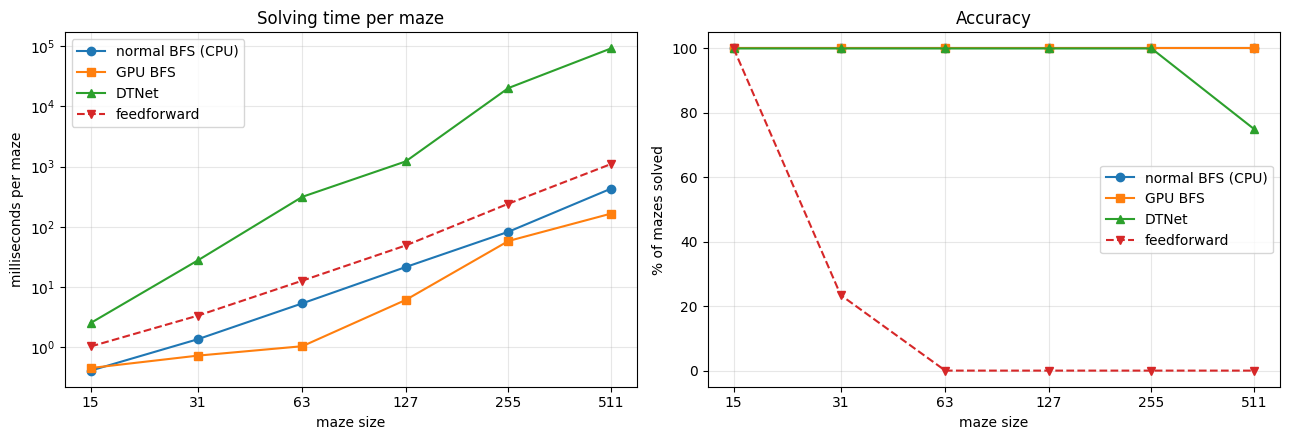

In [14]:
# GRAPH: SOLVING TIME AND ACCURACY VS MAZE SIZE
# Left: time per maze (log scale). Right: % of mazes solved. One line per method.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
styles = {"normal BFS (CPU)": "o-", "GPU BFS": "s-", "DTNet": "^-", "feedforward": "v--"}

for method, style in styles.items():
    r = results[results["method"] == method]
    ax1.plot(r["size"], r["ms_per_maze"], style, label=method)
    ax2.plot(r["size"], 100 * r["accuracy"], style, label=method)

sizes = sorted(results["size"].unique())
ax1.set(xscale="log", yscale="log", xlabel="maze size", ylabel="milliseconds per maze",
        title="Solving time per maze")
ax2.set(xscale="log", xlabel="maze size", ylabel="% of mazes solved",
        title="Accuracy", ylim=(-5, 105))
for ax in (ax1, ax2):
    ax.set_xticks(sizes, [str(s) for s in sizes])
    ax.minorticks_off()
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
fig.savefig("speed_comparison.png", dpi=150)
plt.show()

In [15]:
# SAVE THE RESULTS
# Downloads the results table and the graph to computer

from google.colab import files

results.to_csv("speed_comparison.csv", index=False)
files.download("speed_comparison.csv")
files.download("speed_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>